# Chapitre 1 - Cours 2 : auto-supervision, échelle et modèles de fondation

Ce notebook couvre la suite de la section *The Rise of AI Engineering* : le volet
*Self-supervision* de *From Language Models to Large Language Models*, puis les
sous-sections *From Large Language Models to Foundation Models* et *From Foundation
Models to AI Engineering*. Le fil conducteur du livre tient en un mot : **l'échelle**.
Nous allons voir pourquoi l'auto-supervision l'a rendue possible, la mesurer (paramètres,
données, calcul) et suivre ses conséquences : des modèles multimodaux et généralistes,
qu'on adapte au lieu de les entraîner, d'où la naissance de l'AI engineering.

Plan :

1. supervision contre auto-supervision (et le coût de l'étiquetage) ;
2. comment un texte devient des paires d'entraînement (et la perte associée) ;
3. combien de paramètres ? (croissance, formule, mémoire) ;
4. pourquoi les gros modèles ont besoin de plus de données (règle de Chinchilla, FLOP) ;
5. des LLM aux modèles de fondation : la multimodalité (tokens d'image, apprentissage
   contrastif à la CLIP) ;
6. du modèle spécialisé au modèle généraliste ;
7. adapter un modèle : prompt, RAG, finetuning ;
8. des modèles de fondation à l'AI engineering.

In [1]:
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from aie.plotting import (INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN, LIGHT,
                          annotate_bars, finish)
from aie.diagrams import Diagram
from aie import llm
from aie import ch01_introduction as c1

c1.setup_style()
llm.seed_everything(0)
pd.set_option("display.max_colwidth", 100)

## 1. Supervision contre auto-supervision (section *Self-supervision*)

**Le problème.** Pourquoi les modèles de langage, plutôt que les modèles de détection
d'objets ou de recommandation, ont-ils été au cœur de la course à l'échelle ? Parce que
leur apprentissage ne demande **aucune étiquette humaine**.

- En **apprentissage supervisé**, chaque exemple $x$ doit être accompagné d'une étiquette
  $y$ fournie par un humain (« fraude » / « pas fraude », « chat » / « chien »). C'est le
  paradigme des années 2010 (AlexNet sur ImageNet).
- En **auto-supervision**, les étiquettes sont **déduites des données elles-mêmes** : dans
  un texte, chaque token sert de cible pour le contexte qui le précède.
- En **non-supervisé** (clustering, par exemple), il n'y a pas d'étiquette du tout.

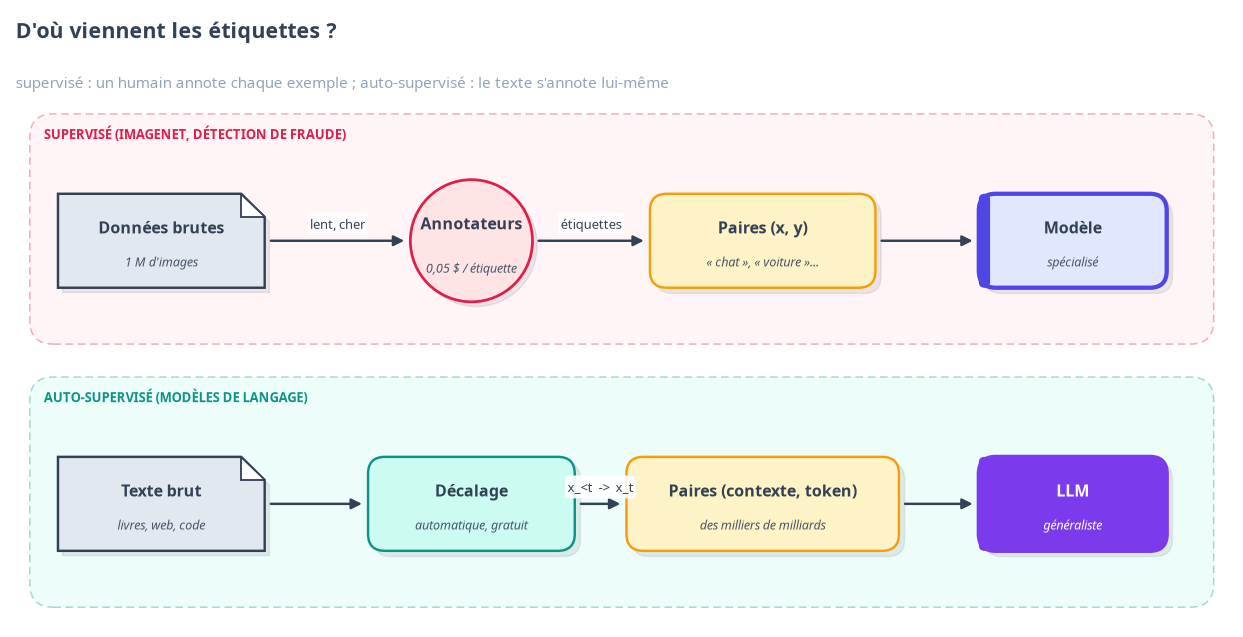

In [2]:
d = Diagram(13, 5.6, title="D'où viennent les étiquettes ?",
            subtitle="supervisé : un humain annote chaque exemple ; auto-supervisé : le texte s'annote lui-même")
d.group(0.2, 3.0, 12.8, 5.45, "Supervisé (ImageNet, détection de fraude)", ROSE)
d.box("img", 1.6, 4.1, "Données brutes", sub="1 M d'images", color=SLATE, kind="doc", w=2.2, h=1.0)
d.box("hum", 4.9, 4.1, "Annotateurs", sub="0,05 $ / étiquette", color=ROSE, kind="user", w=1.3)
d.box("lab", 8.0, 4.1, "Paires (x, y)", sub="« chat », « voiture »...", color=AMBER, w=2.4, h=1.0)
d.box("m1", 11.3, 4.1, "Modèle", sub="spécialisé", color=INDIGO, kind="model", w=2.0, h=1.0)
d.arrow("img", "hum", "lent, cher")
d.arrow("hum", "lab", "étiquettes")
d.arrow("lab", "m1")
d.group(0.2, 0.2, 12.8, 2.65, "Auto-supervisé (modèles de langage)", TEAL)
d.box("txt", 1.6, 1.3, "Texte brut", sub="livres, web, code", color=SLATE, kind="doc", w=2.2, h=1.0)
d.box("auto", 4.9, 1.3, "Décalage", sub="automatique, gratuit", color=TEAL, w=2.2, h=1.0)
d.box("pairs", 8.0, 1.3, "Paires (contexte, token)", sub="des milliers de milliards", color=AMBER, w=2.9, h=1.0)
d.box("m2", 11.3, 1.3, "LLM", sub="généraliste", color=VIOLET, kind="model", w=2.0, h=1.0, filled=True)
d.arrow("txt", "auto")
d.arrow("auto", "pairs", "x_<t  ->  x_t")
d.arrow("pairs", "m2")
d.show()

**Ordres de grandeur.** Reprenons le calcul du livre : à 5 centimes l'étiquette, annoter
le million d'images d'ImageNet coûte 50 000 $, le double avec deux annotateurs par image
(pour contrôler la qualité). Passer de 1 000 à un million de catégories multiplie le coût
par mille. Comparons avec ce qu'aurait coûté l'« étiquetage » du corpus de pré-entraînement
d'un LLM moderne (15 000 milliards de tokens pour Llama 3) si chaque cible devait être
fournie par un humain, même à un dixième de centime.

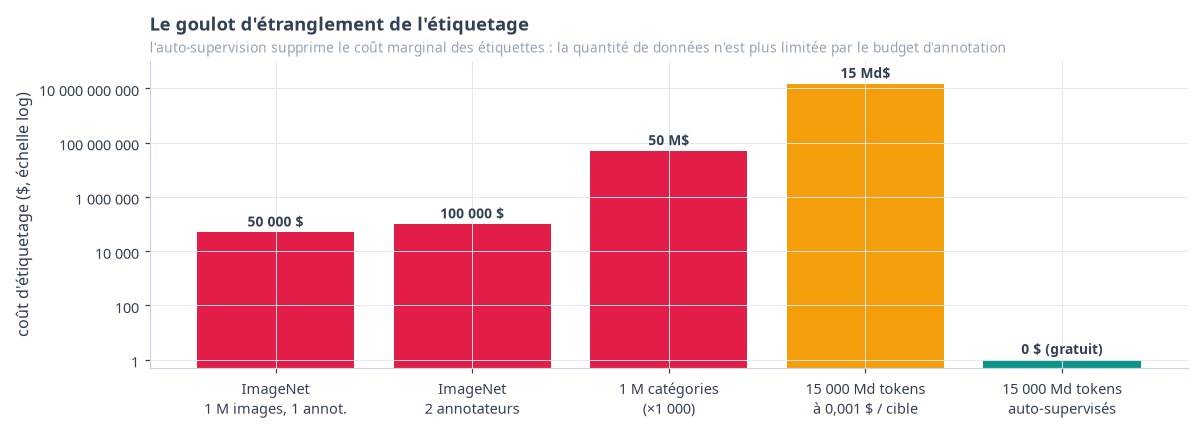

In [3]:
scen = {
    "ImageNet\n1 M images, 1 annot.": c1.labeling_cost(1e6, 0.05),
    "ImageNet\n2 annotateurs": c1.labeling_cost(1e6, 0.05, 2),
    "1 M catégories\n(×1 000)": c1.labeling_cost(1e9, 0.05),
    "15 000 Md tokens\nà 0,001 $ / cible": c1.labeling_cost(15e12, 0.001),
    "15 000 Md tokens\nauto-supervisés": 0.0,
}
fig, ax = plt.subplots(figsize=(11, 4))
vals = np.array(list(scen.values()))
ax.bar(list(scen), np.maximum(vals, 1), color=[ROSE, ROSE, ROSE, AMBER, TEAL])
ax.set_yscale("log"); c1.plain_log(ax)
for i, v in enumerate(vals):
    lab = ("0 $ (gratuit)" if v == 0 else f"{v / 1e9:,.0f} Md$" if v >= 1e9 else
           f"{v / 1e6:,.0f} M$" if v >= 1e6 else f"{v:,.0f} $")
    ax.text(i, max(v, 1) * 1.6, lab.replace(",", " "), ha="center", fontsize=9, fontweight="bold")
ax.set_ylabel("coût d'étiquetage ($, échelle log)")
ax.set_ylim(0.5, 1e11)
c1.title_sub(ax, "Le goulot d'étranglement de l'étiquetage",
             "l'auto-supervision supprime le coût marginal des étiquettes : la quantité de données n'est plus limitée par le budget d'annotation")
plt.tight_layout(); plt.show()

> **À retenir.** L'auto-supervision fait disparaître le coût d'étiquetage : chaque texte
> fournit à la fois les entrées et les cibles. C'est ce qui a permis d'entraîner les
> modèles de langage sur des quantités de données sans commune mesure avec ImageNet.

## 2. Comment un texte devient des paires d'entraînement (section *Self-supervision*)

Le livre illustre l'idée avec une phrase de cinq tokens qui donne six exemples
d'entraînement. Le principe : on encadre la séquence par deux tokens spéciaux, `<BOS>`
(début) et `<EOS>` (fin), puis chaque position fournit une paire (tout ce qui précède,
token courant). Le token `<EOS>` est crucial : c'est en apprenant à le prédire que le
modèle apprend **à s'arrêter**. Faisons-le avec la fonction `autoregressive_pairs` du
module, sur une phrase française découpée en mots.

In [4]:
phrase = ["J'", "adore", "la", "cuisine", "de", "rue", "."]
c1.pairs_table(c1.autoregressive_pairs(phrase))

,entrée (contexte),sortie (prochain token)
0,<BOS>,J'
1,<BOS> J',adore
2,<BOS> J' adore,la
3,<BOS> J' adore la,cuisine
4,<BOS> J' adore la cuisine,de
5,<BOS> J' adore la cuisine de,rue
6,<BOS> J' adore la cuisine de rue,.
7,<BOS> J' adore la cuisine de rue .,<EOS>


Une phrase de $n$ tokens donne donc $n + 1$ paires (avec `<EOS>`). En pratique, on
travaille avec les vrais tokens du modèle, et les paires sont implicites : on donne au
réseau la séquence entière **en une seule passe**, et il produit une prédiction à chaque
position. Les cibles sont la même séquence **décalée d'un cran** ; le masque causal (cours
1) garantit qu'aucune position ne « triche » en regardant sa cible. C'est le *teacher
forcing*.

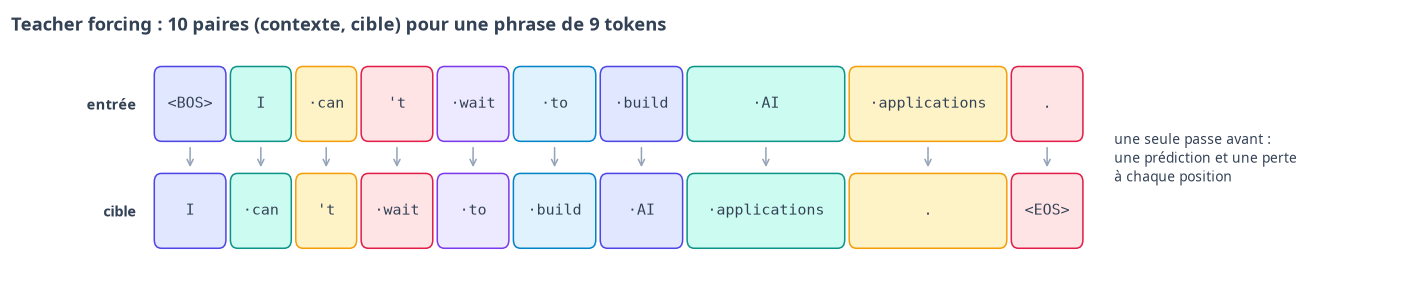

In [5]:
tok_g = c1.get_tokenizer("GPT-2")
sent = "I can't wait to build AI applications."
pieces = tok_g.pieces(sent)
inp = ["<BOS>"] + pieces
tgt = pieces + ["<EOS>"]
fig, ax = plt.subplots(figsize=(13, 2.7))
col_w = [max(0.45, 0.12 * max(len(a), len(b)) + 0.2) for a, b in zip(inp, tgt)]
x_end = c1.draw_tokens(ax, inp, y=1.0, x0=1.6, label="entrée", fontsize=9.5, widths=col_w)
c1.draw_tokens(ax, tgt, y=0.0, x0=1.6, label="cible", fontsize=9.5, widths=col_w)
xc = 1.6
for w in col_w:  # la position t de l'entrée prédit la position t de la cible
    ax.annotate("", xy=(xc + w / 2, 0.38), xytext=(xc + w / 2, 0.62), arrowprops=dict(arrowstyle="->", color=GRAY))
    xc += w + 0.05
ax.text(x_end + 0.3, 0.5, "une seule passe avant :\nune prédiction et une perte\nà chaque position",
        fontsize=9, va="center", color=SLATE)
ax.set_xlim(0, 15.6); ax.set_ylim(-0.6, 1.6); ax.axis("off")
ax.set_title(f"Teacher forcing : {len(tgt)} paires (contexte, cible) pour une phrase de {len(pieces)} tokens", loc="left")
plt.tight_layout(); plt.show()

**La perte associée.** Pour chaque paire, le modèle est pénalisé par la **surprise**
$-\log p_\theta(x_t \mid x_{<t})$ qu'il attribue au vrai token. La perte d'entraînement est
la moyenne de ces surprises, l'**entropie croisée** :
$$\mathcal L(\theta) = -\frac{1}{T} \sum_{t=1}^{T} \log p_\theta(x_t \mid x_{<t}),
  \qquad \text{perplexité} = e^{\mathcal L}.$$
La perplexité s'interprète comme le nombre de tokens entre lesquels le modèle hésite « en
moyenne » (chapitre 3). Mesurons la surprise de GPT-2 sur chaque paire de notre phrase.

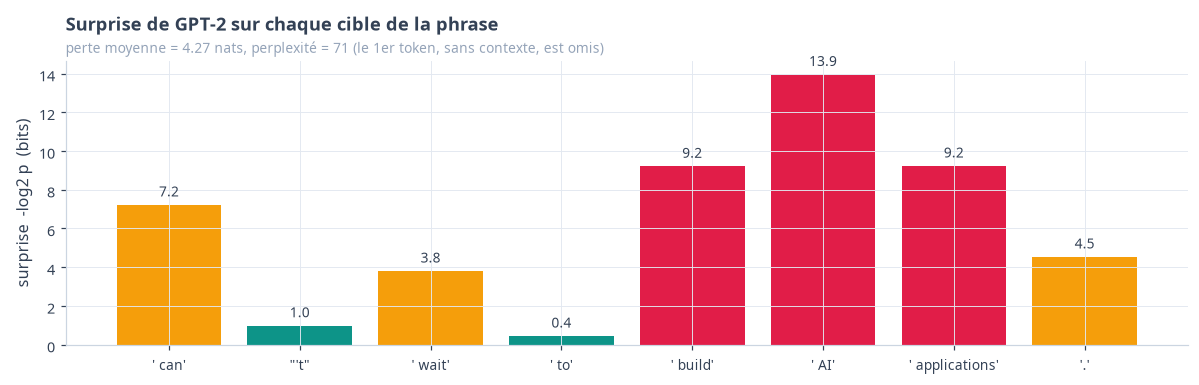

In [6]:
toks, lp = llm.token_logprobs(sent, llm.BASE)
surprise_bits = -lp / np.log(2)
fig, ax = plt.subplots(figsize=(11, 3.6))
cols = [ROSE if s > 8 else (AMBER if s > 3 else TEAL) for s in surprise_bits]
ax.bar(range(len(toks)), surprise_bits, color=cols)
ax.set_xticks(range(len(toks)), [repr(t) for t in toks], rotation=0, fontsize=9)
ax.set_ylabel("surprise  -log2 p  (bits)")
annotate_bars(ax, "{:.1f}")
c1.title_sub(ax, "Surprise de GPT-2 sur chaque cible de la phrase",
             f"perte moyenne = {-lp.mean():.2f} nats, perplexité = {np.exp(-lp.mean()):.0f} "
             "(le 1er token, sans contexte, est omis)")
plt.tight_layout(); plt.show()

« 't » après « can » et « to » après « can't wait » sont quasi certains (moins d'un bit de
surprise) : GPT-2 a vu ces suites des millions de fois. « build », « AI » et
« applications » le surprennent bien davantage (le sujet de la phrase est imprévisible) : ce sont précisément ces cas que l'entraînement améliore, en ajustant les
paramètres $\theta$ par descente de gradient sur $\mathcal L$.

**Combien de paires ?** Un corpus de $N$ tokens fournit environ $N$ paires (une par
position). Avec une fenêtre de contexte de longueur $C$, on découpe le corpus en
$\lceil N / C \rceil$ séquences, chacune traitée en une passe.

In [7]:
for N, name in [(5e9, "Wikipédia anglophone (~5 Md tokens)"), (300e9, "GPT-3 (300 Md tokens)"),
                (15e12, "Llama 3 (15 000 Md tokens)")]:
    print(f"{name:38s} -> {N:9.1e} paires ; {N / 8192:9.2e} séquences de 8 192 tokens")

Wikipédia anglophone (~5 Md tokens)    ->   5.0e+09 paires ;  6.10e+05 séquences de 8 192 tokens
GPT-3 (300 Md tokens)                  ->   3.0e+11 paires ;  3.66e+07 séquences de 8 192 tokens
Llama 3 (15 000 Md tokens)             ->   1.5e+13 paires ;  1.83e+09 séquences de 8 192 tokens


> **À retenir.** Une séquence de $n$ tokens donne $n$ (ou $n+1$) exemples d'entraînement
> gratuits ; une passe avant les traite tous à la fois grâce au masque causal. La perte
> est la surprise moyenne (entropie croisée) ; son exponentielle est la perplexité.

## 3. Combien de paramètres ? (section *Self-supervision*, sur les LLM)

Le livre souligne que « large » n'a rien de scientifique : GPT-1 (117 M de paramètres,
2018) était « grand » jusqu'à l'arrivée de GPT-2 (1,5 Md, 2019) ; au moment de la
rédaction, « grand » signifie plutôt 100 Md. Un **paramètre** est une variable du modèle
ajustée pendant l'entraînement (on dit aussi « poids »). Visualisons la croissance avec
les tailles publiées de quelques modèles marquants.

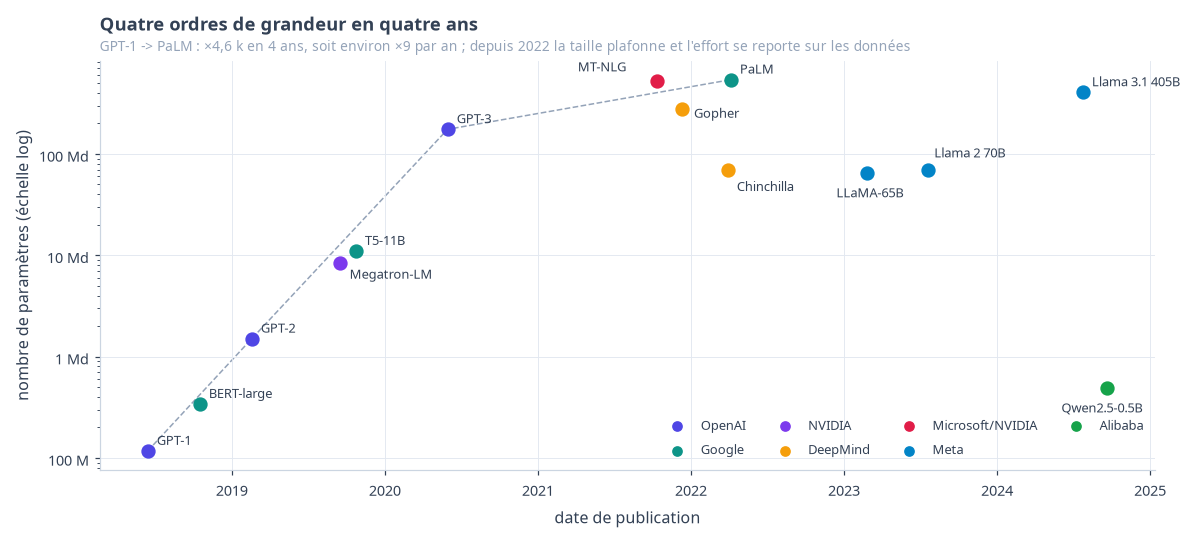

In [8]:
ms = c1.model_sizes_frame()
fig, ax = plt.subplots(figsize=(11, 5))
orgs = ms["organisation"].unique()
cmap = dict(zip(orgs, [INDIGO, TEAL, VIOLET, AMBER, ROSE, SKY, GREEN, SLATE]))
for _, r in ms.iterrows():
    ax.scatter(r["date"], r["params_Md"] * 1e9, s=70, color=cmap[r["organisation"]], zorder=5)
    off = {"Chinchilla": (6, -14), "Megatron-LM": (6, -10), "MT-NLG": (-52, 6), "PaLM": (6, 4),
           "Gopher": (8, -6), "Qwen2.5-0.5B": (-30, -16), "LLaMA-65B": (-20, -16),
           "Llama 2 70B": (4, 8)}.get(r["modèle"], (6, 4))
    ax.annotate(r["modèle"], (r["date"], r["params_Md"] * 1e9), textcoords="offset points",
                xytext=off, fontsize=8.5)
big = ms[ms["modèle"].isin(["GPT-1", "GPT-2", "GPT-3", "PaLM"])]
slope = np.polyfit(big["date"], np.log10(big["params_Md"] * 1e9), 1)[0]
ax.plot(big["date"], big["params_Md"] * 1e9, color=GRAY, ls="--", lw=1, zorder=1)
ax.set_yscale("log"); c1.human_log(ax)
ax.set_ylabel("nombre de paramètres (échelle log)")
ax.set_xlabel("date de publication")
for o, ccol in cmap.items():
    ax.scatter([], [], color=ccol, label=o)
ax.legend(ncol=4, loc="lower right", fontsize=8.5)
c1.title_sub(ax, "Quatre ordres de grandeur en quatre ans",
             f"GPT-1 -> PaLM : ×{c1.human_number(540 / 0.117)} en 4 ans, soit environ ×{10 ** slope:.0f} par an ; "
             "depuis 2022 la taille plafonne et l'effort se reporte sur les données")
plt.tight_layout(); plt.show()

**D'où viennent ces nombres ?** Pour un transformer décodeur de $L$ couches et de
dimension $d$, chaque couche contient l'attention (4 matrices $d \times d$ : requêtes,
clés, valeurs, sortie) et un MLP (deux matrices $d \times 4d$), soit environ
$4d^2 + 8d^2 = 12 d^2$ paramètres. En ajoutant la table d'embeddings $V \times d$ :
$$N \approx 12\,L\,d^2 + V d.$$
Pour GPT-3 ($L = 96$, $d = 12\,288$) : $12 \times 96 \times 12\,288^2 \approx 174$ Md, plus
0,6 Md d'embeddings : on retrouve les 175 Md annoncés. Vérifions la formule (et sa
variante moderne) contre le décompte exact de deux modèles locaux, chargés sur CPU.

In [9]:
from transformers import AutoConfig, AutoModelForCausalLM

rows = []
for mid in [llm.BASE, llm.SMALL]:
    cfg = AutoConfig.from_pretrained(mid)
    model_cpu = AutoModelForCausalLM.from_pretrained(mid, dtype="auto", device_map="cpu")
    exact = llm.count_params(model_cpu)
    del model_cpu
    if mid == llm.BASE:
        est = c1.transformer_params(cfg.n_layer, cfg.n_embd, cfg.vocab_size, n_ctx=cfg.n_positions)
        arch = f"L={cfg.n_layer}, d={cfg.n_embd}, V={cfg.vocab_size}"
    else:  # Qwen2.5 : MLP « gated » (SwiGLU), attention à requêtes groupées (GQA)
        kv = cfg.num_key_value_heads / cfg.num_attention_heads
        est = c1.transformer_params(cfg.num_hidden_layers, cfg.hidden_size, cfg.vocab_size,
                                    d_ff=cfg.intermediate_size, gated=True, kv_ratio=kv,
                                    tied=cfg.tie_word_embeddings)
        arch = (f"L={cfg.num_hidden_layers}, d={cfg.hidden_size}, d_ff={cfg.intermediate_size}, "
                f"V={cfg.vocab_size}, GQA {cfg.num_key_value_heads}/{cfg.num_attention_heads}")
    rows.append({"modèle": mid, "architecture": arch, "estimation": f"{est / 1e6:.1f} M",
                 "décompte exact": f"{exact / 1e6:.1f} M", "écart": f"{(est - exact) / exact:+.1%}",
                 "part des embeddings": f"{cfg.vocab_size * (cfg.n_embd if mid == llm.BASE else cfg.hidden_size) / exact:.0%}"})
pd.DataFrame(rows)

,modèle,architecture,estimation,décompte exact,écart,part des embeddings
0,gpt2,"L=12, d=768, V=50257",124.3 M,124.4 M,-0.1%,31%
1,Qwen/Qwen2.5-0.5B-Instruct,"L=24, d=896, d_ff=4864, V=151936, GQA 2/14",494.0 M,494.0 M,-0.0%,28%


La formule tombe à moins de 1 % près (l'écart restant vient des biais et normalisations,
négligés). Détail instructif : pour ces **petits** modèles, la table d'embeddings pèse
lourd (un tiers des paramètres de GPT-2, plus d'un quart de Qwen2.5-0.5B avec son
vocabulaire de 151 k tokens), alors qu'elle est négligeable pour GPT-3. La taille du
vocabulaire est donc un vrai choix d'architecture (chapitre 2).

**Ce que cela coûte en mémoire.** Stocker les poids en bf16 demande 2 octets par
paramètre (le chapitre 7 montre comment la quantification réduit ce chiffre).

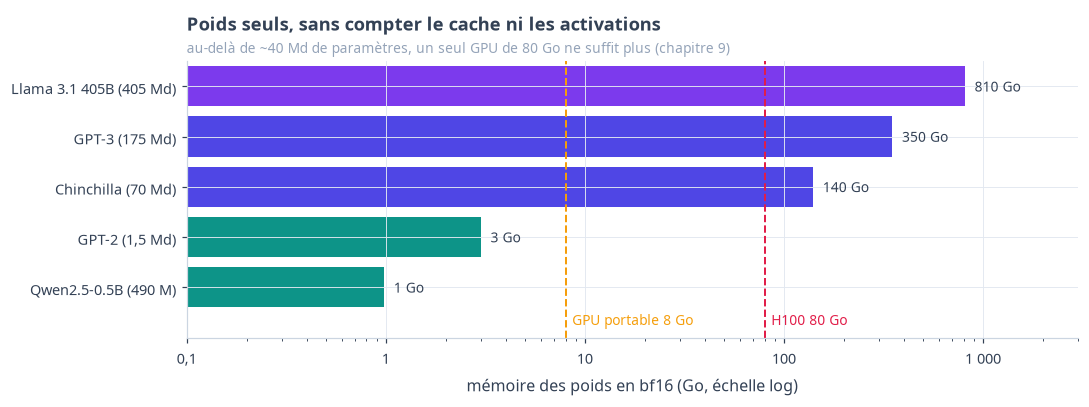

In [10]:
sel = ["Qwen2.5-0.5B", "GPT-2", "Chinchilla", "GPT-3", "Llama 3.1 405B"]
mem = {f"{m} ({c1.human_number(ms.loc[ms['modèle'] == m, 'params_Md'].item() * 1e9)})":
       c1.weights_memory_gb(ms.loc[ms["modèle"] == m, "params_Md"].item() * 1e9) for m in sel}
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.barh(list(mem), list(mem.values()), color=[TEAL, TEAL, INDIGO, INDIGO, VIOLET])
ax.set_xscale("log"); c1.plain_log(ax, "x")
for gpu, gb, col in [("GPU portable 8 Go", 8, AMBER), ("H100 80 Go", 80, ROSE)]:
    ax.axvline(gb, color=col, ls="--", lw=1.3)
    ax.text(gb * 1.08, -0.75, gpu, color=col, fontsize=9)
for i, v in enumerate(mem.values()):
    ax.text(v * 1.12, i, f"{v:,.0f} Go".replace(",", " "), va="center", fontsize=9)
ax.set_ylim(-1, len(mem) - 0.5)
ax.set_xlabel("mémoire des poids en bf16 (Go, échelle log)")
c1.title_sub(ax, "Poids seuls, sans compter le cache ni les activations",
             "au-delà de ~40 Md de paramètres, un seul GPU de 80 Go ne suffit plus (chapitre 9)")
ax.set_xlim(0.1, 3000)
plt.tight_layout(); plt.show()

> **À retenir.** La taille d'un modèle se mesure en paramètres, $N \approx 12 L d^2 + V d$
> pour un transformer classique. Le seuil du « grand » se déplace sans cesse ; la mémoire
> nécessaire ($2N$ octets en bf16) est la première contrainte d'ingénierie.

## 4. Pourquoi les gros modèles ont besoin de plus de données (section *Self-supervision*, sur les LLM)

Le livre pose une question souvent éludée : pourquoi un modèle plus grand demanderait-il
plus de données, alors qu'il est plus « capable » ? Parce qu'on ne cherche pas à égaler
un petit modèle avec moins de données, mais à **maximiser** la performance : plus de
capacité permet d'absorber plus d'information, et entraîner un grand modèle sur peu de
données gaspille du calcul. Les lois d'échelle (chapitre 2) précisent cette intuition.
L'étude « Chinchilla » (Hoffmann et al., 2022) conclut qu'à budget de calcul fixé, il faut
environ **20 tokens d'entraînement par paramètre** :
$$D^\star \approx 20\,N, \qquad C \approx 6\,N\,D \ \text{FLOP}.$$
Le facteur 6 vient de 2 FLOP par paramètre et par token pour la passe avant
(une multiplication et une addition), et environ le double pour la passe arrière.

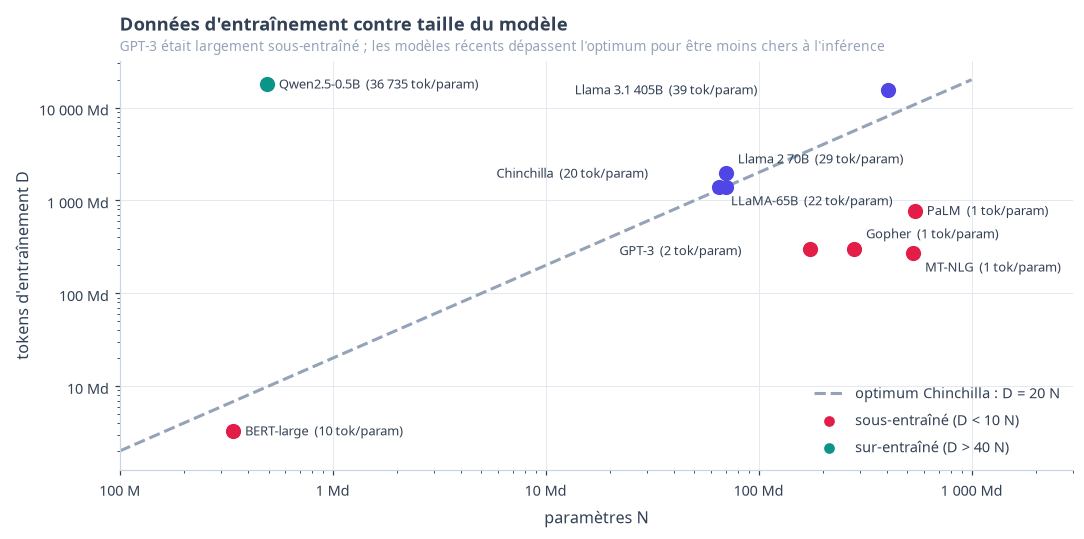

In [11]:
known = ms.dropna(subset=["tokens_Md"])
fig, ax = plt.subplots(figsize=(10, 5))
N_grid = np.logspace(8, 12, 50)
ax.plot(N_grid, c1.chinchilla_tokens(N_grid), color=GRAY, ls="--", label="optimum Chinchilla : D = 20 N")
for _, r in known.iterrows():
    N, D = r["params_Md"] * 1e9, r["tokens_Md"] * 1e9
    col = ROSE if D < 10 * N else (TEAL if D > 40 * N else INDIGO)
    ax.scatter(N, D, s=80, color=col, zorder=5)
    off = {"Chinchilla": (-150, 6), "LLaMA-65B": (8, -12), "Llama 2 70B": (8, 6), "GPT-3": (-125, -4),
           "Gopher": (8, 7), "MT-NLG": (8, -12), "Llama 3.1 405B": (-205, -3)}.get(r["modèle"], (8, -3))
    ax.annotate(f"{r['modèle']}  ({D / N:,.0f} tok/param)".replace(",", " "), (N, D),
                textcoords="offset points", xytext=off, fontsize=8.5)
ax.set_xscale("log"); ax.set_yscale("log"); c1.human_log(ax, "x"); c1.human_log(ax, "y")
ax.set_xlabel("paramètres N"); ax.set_ylabel("tokens d'entraînement D")
ax.scatter([], [], color=ROSE, label="sous-entraîné (D < 10 N)")
ax.scatter([], [], color=TEAL, label="sur-entraîné (D > 40 N)")
ax.legend(loc="lower right")
c1.title_sub(ax, "Données d'entraînement contre taille du modèle",
             "GPT-3 était largement sous-entraîné ; les modèles récents dépassent l'optimum pour être moins chers à l'inférence")
ax.set_xlim(1e8, 3e12)
plt.tight_layout(); plt.show()

GPT-3 et Gopher (≈ 1 à 2 tokens par paramètre) étaient très en dessous de l'optimum ;
Chinchilla (70 Md, 1 400 Md de tokens) les surpasse avec 2,5 à 4 fois moins de paramètres.
Depuis, on va même **au-delà** de 20 tokens par paramètre (Llama 3, Qwen2.5 avec 18 000 Md
de tokens pour 0,5 Md de paramètres) : à qualité égale, un modèle plus petit coûte moins
cher à servir, et c'est l'inférence qui domine la facture quand un modèle a des millions
d'utilisateurs. Le livre mentionne aussi le revers : on risque de **manquer de données
publiques** sur Internet pour nourrir cette croissance (chapitre 2).

**Le coût en calcul.** Combien de temps faudrait-il pour entraîner ces modèles sur le GPU
portable de ce dépôt (de l'ordre de 50 TFLOP/s en bf16, utilisé à 40 %) ou sur un grand
cluster de 16 000 H100 (≈ 990 TFLOP/s chacun, 40 % d'utilisation) ?

In [12]:
rows = []
for name, N, D in [("GPT-2 (1,5 Md)", 1.5e9, 30e9), ("Chinchilla", 70e9, 1.4e12), ("GPT-3", 175e9, 300e9),
                   ("Llama 3.1 405B", 405e9, 15.6e12)]:
    C = c1.training_flops(N, D)
    laptop_days = C / (50e12 * 0.4) / 86400
    cluster_days = C / (16_000 * 990e12 * 0.4) / 86400
    rows.append({"modèle": name, "calcul C = 6ND (FLOP)": f"{C:.1e}",
                 "GPU portable (années)": f"{laptop_days / 365:,.1f}".replace(",", " ").replace(".", ","),
                 "16 000 H100 (jours)": f"{cluster_days:.1f}"})
pd.DataFrame(rows)

,modèle,calcul C = 6ND (FLOP),GPU portable (années),16 000 H100 (jours)
0,"GPT-2 (1,5 Md)",2.7e+20,"0,4",0.0
1,Chinchilla,5.9e+23,"932,3",1.1
2,GPT-3,3.2e+23,"499,4",0.6
3,Llama 3.1 405B,3.8e+25,"60 102,7",69.2


Llama 3.1 405B représente environ $4 \times 10^{25}$ FLOP : quelque 60 000 ans sur un GPU
portable, et encore plus de deux mois sur 16 000 H100 (ordre de grandeur cohérent avec
ce que Meta a publié : environ 30 millions d'heures-GPU H100). Seule une poignée d'organisations peut financer de tels
entraînements : c'est précisément ce qui a fait émerger le **modèle-service** (*model as a
service*), point de départ du livre.

> **À retenir.** Plus de paramètres appelle plus de données (≈ 20 tokens par paramètre à
> l'optimum de calcul) et un calcul $C \approx 6ND$ qui explose : $10^{25}$ FLOP pour un
> modèle de pointe. D'où la concentration du pré-entraînement chez quelques acteurs.

## 5. Des LLM aux modèles de fondation : la multimodalité (section *From Large Language Models to Foundation Models*)

Un modèle de texte ne perçoit le monde qu'à travers la langue. Les modèles récents
(GPT-4V, Claude 3, Gemini) acceptent aussi des images, parfois de l'audio ou de la vidéo :
on les appelle **modèles multimodaux**, ou **LMM** (*large multimodal models*) quand ils
sont génératifs. Le livre les regroupe avec les LLM sous le terme de **modèles de
fondation** : des modèles sur lesquels on **construit**.

**Comment une image devient-elle des tokens ?** L'approche la plus répandue (Vision
Transformer) découpe l'image en **patchs** carrés (par exemple $14 \times 14$ ou
$16 \times 16$ pixels), projette chaque patch en un vecteur de même dimension qu'un
embedding de token, et place ces « tokens visuels » dans la même séquence que les
tokens de texte. Le modèle prédit ensuite le prochain token de texte conditionné sur
les deux.

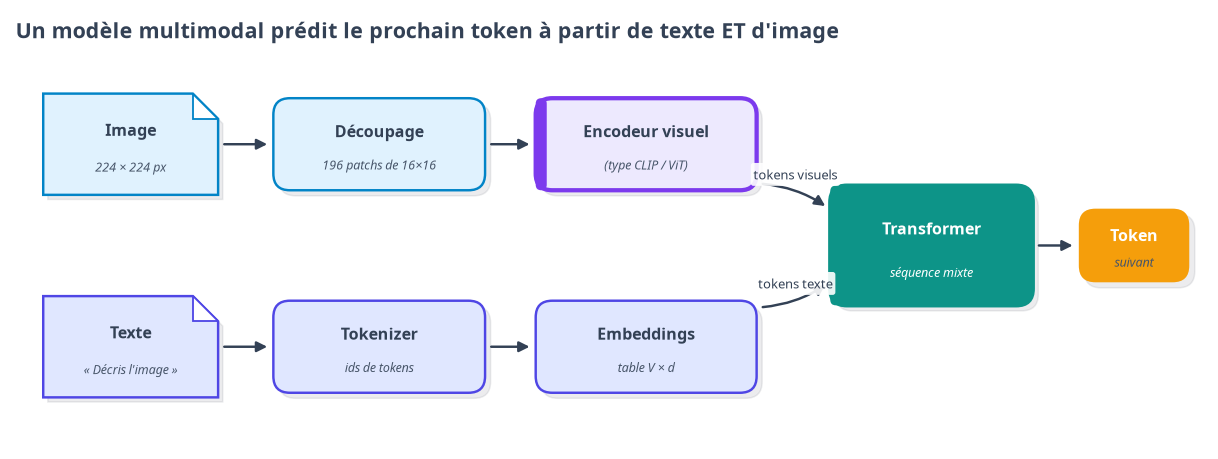

In [13]:
d = Diagram(13, 4.2, title="Un modèle multimodal prédit le prochain token à partir de texte ET d'image")
d.box("img", 1.3, 3.3, "Image", sub="224 × 224 px", color=SKY, kind="doc", w=1.9, h=1.1)
d.box("patch", 4.0, 3.3, "Découpage", sub="196 patchs de 16×16", color=SKY, w=2.3, h=1.0)
d.box("venc", 6.9, 3.3, "Encodeur visuel", sub="(type CLIP / ViT)", color=VIOLET, kind="model", w=2.4, h=1.0)
d.box("txt", 1.3, 1.1, "Texte", sub="« Décris l'image »", color=INDIGO, kind="doc", w=1.9, h=1.1)
d.box("tok", 4.0, 1.1, "Tokenizer", sub="ids de tokens", color=INDIGO, w=2.3, h=1.0)
d.box("emb", 6.9, 1.1, "Embeddings", sub="table V × d", color=INDIGO, w=2.4, h=1.0)
d.box("llm", 10.0, 2.2, "Transformer", sub="séquence mixte", color=TEAL, kind="model", w=2.2, h=1.3, filled=True)
d.box("out", 12.2, 2.2, "Token", sub="suivant", color=AMBER, kind="tag", w=1.2, h=0.8)
d.arrow("img", "patch"); d.arrow("patch", "venc"); d.arrow("venc", "llm", "tokens visuels", rad=-0.15)
d.arrow("txt", "tok"); d.arrow("tok", "emb"); d.arrow("emb", "llm", "tokens texte", rad=0.15)
d.arrow("llm", "out")
d.show()

**Une image vaut combien de tokens ?** Le nombre de patchs est $(H/P) \times (W/P)$. Une
image $224 \times 224$ découpée en patchs de 16 pixels donne $14 \times 14 = 196$ tokens ;
à résolution plus élevée, la facture grimpe vite (quadratiquement avec le côté). Voici
une image synthétique et son découpage.

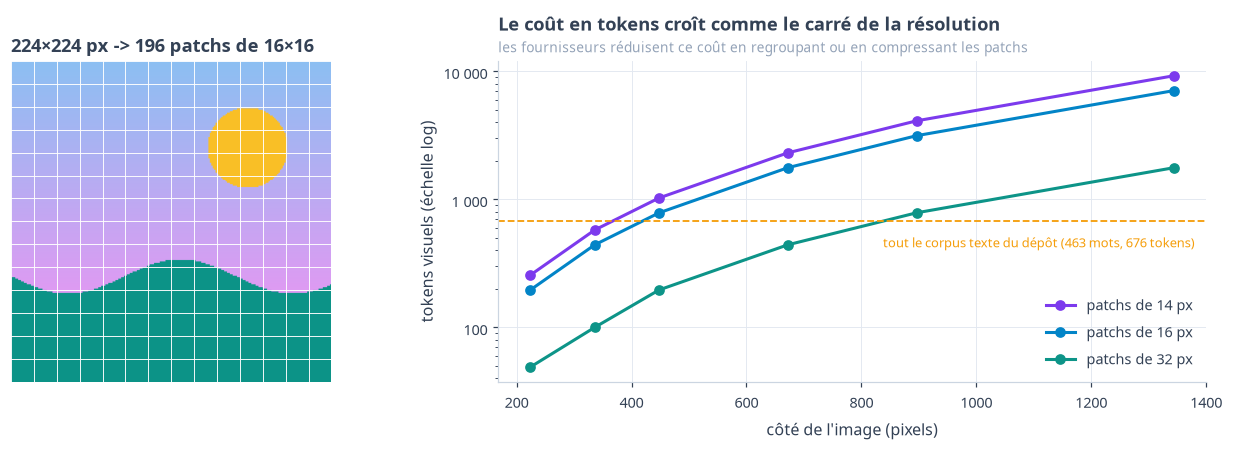

In [14]:
H = W = 224; P = 16
yy, xx = np.mgrid[0:H, 0:W]
img = np.zeros((H, W, 3))
img[..., 0] = 0.55 + 0.45 * (yy / H)           # ciel en dégradé
img[..., 1] = 0.75 - 0.2 * (yy / H)
img[..., 2] = 0.95
sun = (xx - 165) ** 2 + (yy - 60) ** 2 < 28 ** 2
img[sun] = [0.98, 0.75, 0.15]
ground = yy > 150 + 12 * np.sin(xx / 25)
img[ground] = [0.05, 0.58, 0.53]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1.5]})
axes[0].imshow(img)
for k in range(0, H + 1, P):
    axes[0].axhline(k - 0.5, color="white", lw=0.6); axes[0].axvline(k - 0.5, color="white", lw=0.6)
axes[0].set_title(f"{H}×{W} px -> {(H // P) ** 2} patchs de {P}×{P}"); axes[0].axis("off")
res = np.array([224, 336, 448, 672, 896, 1344])
for p_, col in [(14, VIOLET), (16, SKY), (32, TEAL)]:
    axes[1].plot(res, (res // p_) ** 2, "o-", color=col, label=f"patchs de {p_} px")
n_corpus = c1.get_tokenizer("GPT-4o (o200k)").count(c1.CORPUS_FR)
axes[1].axhline(n_corpus, color=AMBER, ls="--", lw=1.2)
axes[1].text(1380, n_corpus * 0.8, f"tout le corpus texte du dépôt ({len(c1.words(c1.CORPUS_FR))} mots, {n_corpus} tokens)",
             color=AMBER, fontsize=8.5, ha="right", va="top")
axes[1].set_yscale("log"); c1.plain_log(axes[1])
axes[1].set_xlabel("côté de l'image (pixels)"); axes[1].set_ylabel("tokens visuels (échelle log)")
axes[1].legend(loc="lower right")
c1.title_sub(axes[1], "Le coût en tokens croît comme le carré de la résolution",
             "les fournisseurs réduisent ce coût en regroupant ou en compressant les patchs")
finish(fig); plt.show()

**Auto-supervision multimodale : la supervision par le langage naturel.** Pour entraîner
CLIP (OpenAI, 2021), personne n'a étiqueté d'images : on a récolté 400 millions de paires
(image, texte) qui **co-apparaissent** sur le web (une image et sa légende), soit 400 fois
ImageNet. L'objectif est **contrastif** : dans un lot de $B$ paires, l'embedding de chaque
image doit être plus proche de celui de **sa** légende que des $B - 1$ autres. Avec la
matrice de similarités $S_{ij} = \cos(u_i, v_j)/\tau$ :
$$\mathcal L = -\frac{1}{B} \sum_{i=1}^{B} \log \frac{e^{S_{ii}}}{\sum_{j} e^{S_{ij}}}
  \quad (\text{plus le terme symétrique}).$$
Nous n'avons pas de modèle image-texte en local ; illustrons le même mécanisme par une
**analogie** : des paires (légende française, légende anglaise), encodées par un modèle
d'embeddings multilingue. Les deux « modalités » sont ici deux langues.

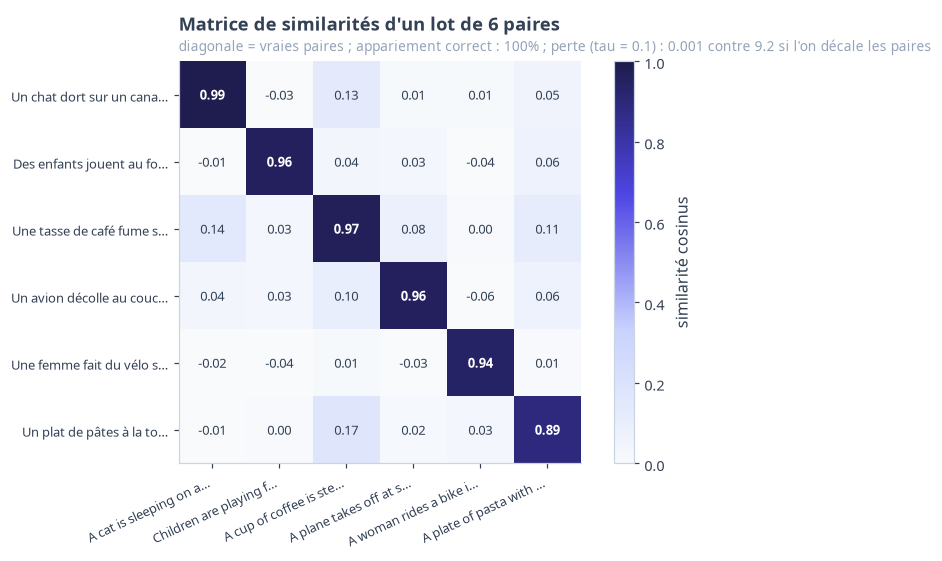

In [15]:
caps = [("Un chat dort sur un canapé rouge.", "A cat is sleeping on a red sofa."),
        ("Des enfants jouent au football dans un parc.", "Children are playing football in a park."),
        ("Une tasse de café fume sur une table en bois.", "A cup of coffee is steaming on a wooden table."),
        ("Un avion décolle au coucher du soleil.", "A plane takes off at sunset."),
        ("Une femme fait du vélo sous la pluie.", "A woman rides a bike in the rain."),
        ("Un plat de pâtes à la tomate et au basilic.", "A plate of pasta with tomato and basil.")]
U = llm.embed([f for f, _ in caps], llm.EMBED_MULTI)
Vv = llm.embed([e for _, e in caps], llm.EMBED_MULTI)
S = U @ Vv.T
tau = 0.1
loss = -np.mean(np.log(np.diag(llm.softmax(S / tau))))
perm = np.roll(np.arange(len(caps)), 1)          # mauvais appariement : chaque légende avec la suivante
loss_bad = -np.mean(np.log(llm.softmax(S / tau)[np.arange(len(caps)), perm]))
fig, ax = plt.subplots(figsize=(8.5, 5.2))
im = ax.imshow(S, cmap="aie_seq", vmin=0, vmax=1)
ax.set_xticks(range(len(caps)), [e[:22] + "…" for _, e in caps], rotation=25, ha="right", fontsize=8.5)
ax.set_yticks(range(len(caps)), [f[:24] + "…" for f, _ in caps], fontsize=8.5)
ax.grid(False)
for i in range(len(caps)):
    for j in range(len(caps)):
        ax.text(j, i, f"{S[i, j]:.2f}", ha="center", va="center", fontsize=8.5,
                color="white" if S[i, j] > 0.6 else SLATE, fontweight="bold" if i == j else "normal")
acc = np.mean(S.argmax(1) == np.arange(len(caps)))
c1.title_sub(ax, "Matrice de similarités d'un lot de 6 paires",
             f"diagonale = vraies paires ; appariement correct : {acc:.0%} ; perte (tau = {tau}) : {loss:.3f} "
             f"contre {loss_bad:.1f} si l'on décale les paires")
plt.colorbar(im, ax=ax, fraction=0.04, label="similarité cosinus")
plt.tight_layout(); plt.show()

La diagonale domine : chaque légende retrouve sa traduction parmi les six candidates, et
la perte contrastive est presque nulle, alors qu'elle serait très élevée pour des paires
mal appariées : c'est ce signal que l'entraînement contrastif exploite. CLIP fait exactement cela avec des images à la place
d'une des deux langues ; ses embeddings conjoints servent ensuite de colonne vertébrale
aux modèles multimodaux génératifs (Flamingo, LLaVA, Gemini). Notez que CLIP lui-même
n'est **pas génératif** : c'est un modèle d'**embeddings** (chapitre 6).

> **À retenir.** Un modèle de fondation multimodal traite images et texte comme une seule
> séquence de tokens (une image ≈ des centaines de tokens). L'auto-supervision s'étend aux
> images grâce aux paires (image, légende) du web et à un objectif contrastif.

## 6. Du modèle spécialisé au modèle généraliste (section *From Large Language Models to Foundation Models*)

Avant les modèles de fondation, on entraînait **un modèle par tâche** : un pour le
sentiment, un pour la traduction, un pour l'extraction d'entités... chacun avec ses
données étiquetées. Un modèle de fondation, par son échelle et son mode d'entraînement,
sait faire « assez bien » une grande variété de tâches (le livre cite les 1 600 tâches du
benchmark Super-NaturalInstructions). Testons un seul petit modèle, Qwen2.5-0.5B, sur
quatre tâches différentes, uniquement en changeant l'instruction.

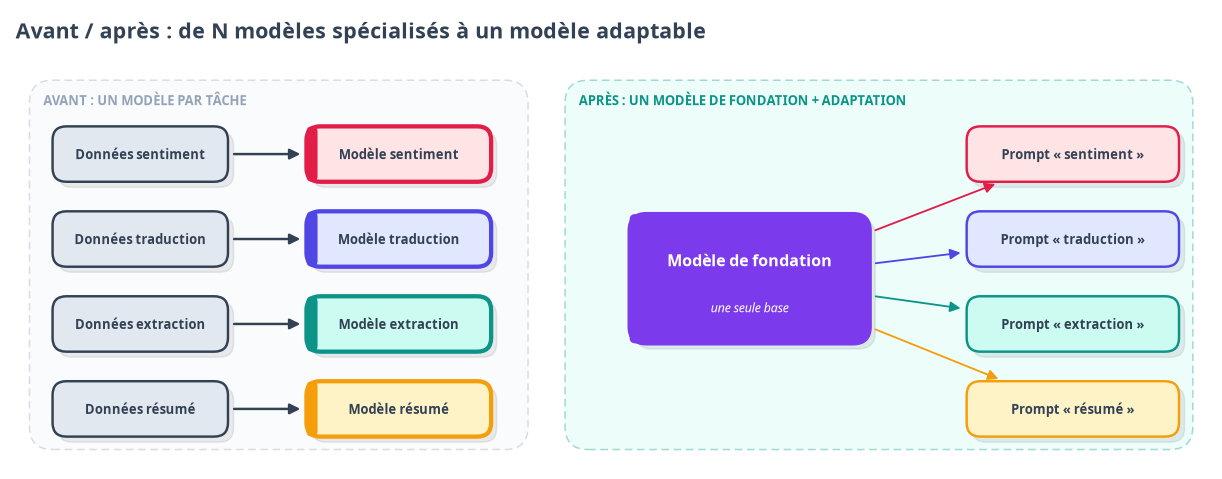

In [16]:
d = Diagram(13, 4.4, title="Avant / après : de N modèles spécialisés à un modèle adaptable")
d.group(0.2, 0.2, 5.6, 4.2, "Avant : un modèle par tâche", GRAY)
tasks = [("Sentiment", ROSE), ("Traduction", INDIGO), ("Extraction", TEAL), ("Résumé", AMBER)]
for i, (t, col) in enumerate(tasks):
    y = 3.4 - i * 0.92
    d.box(f"dat{i}", 1.4, y, f"Données {t.lower()}", color=SLATE, w=1.9, h=0.6, fontsize=8.5)
    d.box(f"mod{i}", 4.2, y, f"Modèle {t.lower()}", color=col, kind="model", w=2.0, h=0.6, fontsize=8.5)
    d.arrow(f"dat{i}", f"mod{i}")
d.group(6.0, 0.2, 12.8, 4.2, "Après : un modèle de fondation + adaptation", TEAL)
d.box("fm", 8.0, 2.05, "Modèle de fondation", sub="une seule base", color=VIOLET, kind="model", w=2.6, h=1.4, filled=True)
for i, (t, col) in enumerate(tasks):
    y = 3.4 - i * 0.92
    d.box(f"p{i}", 11.5, y, f"Prompt « {t.lower()} »", color=col, w=2.3, h=0.6, fontsize=8.5)
    d.arrow("fm", f"p{i}", color=col, lw=1.2)
d.show()

In [17]:
review = "Livraison rapide mais le produit est arrivé cassé, et le service client ne répond pas."
tasks_prompts = {
    "sentiment": f"Quel est le sentiment de cet avis (positif, négatif ou mitigé) ? Réponds en un mot.\nAvis : {review}",
    "traduction": f"Traduis en anglais : {review}",
    "extraction": f"Liste les problèmes mentionnés dans cet avis, sous forme de liste JSON de chaînes.\nAvis : {review}",
    "résumé": f"Résume cet avis en moins de 10 mots.\nAvis : {review}",
}
outs = {k: llm.chat(p, llm.SMALL, max_new_tokens=60) for k, p in tasks_prompts.items()}
pd.DataFrame({"tâche": list(outs), "réponse de Qwen2.5-0.5B-Instruct":
              [re.sub(r"\s+", " ", o)[:150] for o in outs.values()]})

,tâche,réponse de Qwen2.5-0.5B-Instruct
0,sentiment,Négatif
1,traduction,"""Fast shipping but the product is broken and the customer service doesn't respond."""
2,extraction,Voici la liste des problèmes mentionnés dans l'avis : 1. Livraison rapide 2. Produit cassé 3. Se...
3,résumé,"L'avis: Livraison rapide, produit cassé, service client inapropat."


Un seul modèle de 0,5 Md de paramètres produit des réponses pour les quatre tâches, sans
aucune donnée d'entraînement spécifique. Elles sont loin d'être parfaites, et il faut les
lire d'un œil critique : un avis plutôt « mitigé » peut être classé « négatif », la
« livraison rapide » peut se retrouver dans la liste des problèmes, le résumé peut contenir
un mot approximatif. C'est typique de cette taille de modèle, et c'est tout l'enjeu : un
modèle généraliste
fonctionne **raisonnablement** partout, et on peut l'**adapter** pour qu'il excelle sur
**votre** tâche. Le livre note en contrepartie qu'un modèle spécialisé peut être bien plus
petit, donc plus rapide et moins cher : c'est la classique question **construire ou
acheter** (*buy or build*).

> **À retenir.** Les modèles de fondation marquent le passage de modèles spécialisés à des
> modèles généralistes : une seule base, des usages multiples, définis par l'instruction.

## 7. Adapter un modèle : prompt, RAG, finetuning (section *From Large Language Models to Foundation Models*)

Le livre prend l'exemple d'un commerçant qui veut générer des fiches produits : un modèle
brut peut écrire des descriptions correctes mais sans la voix de la marque, voire pleines
de clichés marketing. Trois techniques d'adaptation, qui structurent tout le livre :

| technique | principe | modifie les poids ? | chapitre |
|---|---|---|---|
| ingénierie de prompt | instructions détaillées + exemples | non | 5 |
| RAG | ajouter au prompt des informations récupérées dans une base (avis clients...) | non | 6 |
| finetuning | poursuivre l'entraînement sur des exemples de haute qualité | oui | 7 |

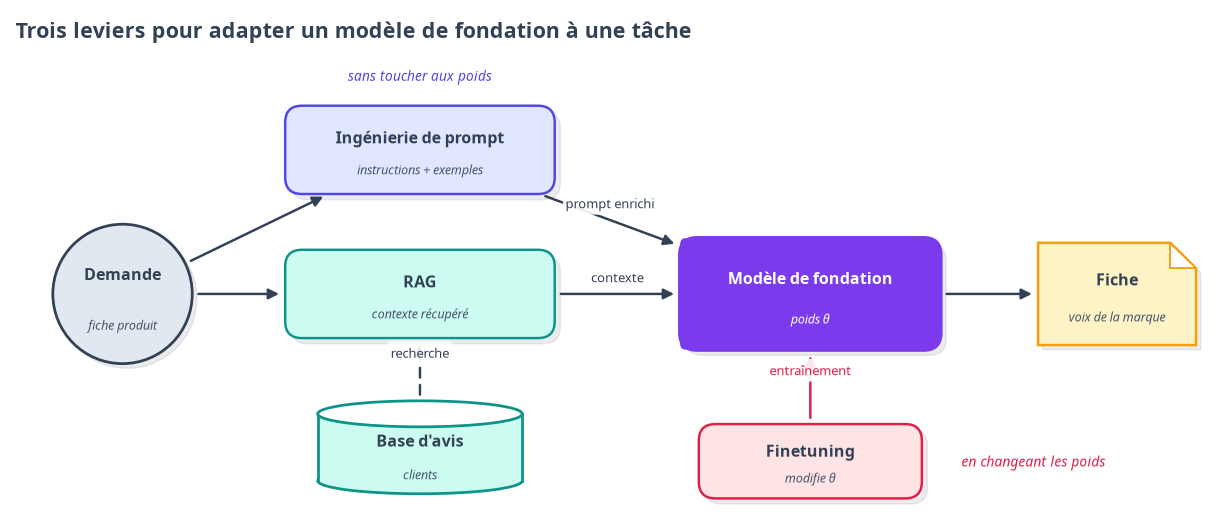

In [18]:
d = Diagram(13, 4.9, title="Trois leviers pour adapter un modèle de fondation à une tâche")
d.box("q", 1.2, 2.4, "Demande", sub="fiche produit", color=SLATE, kind="user", w=1.5)
d.box("pe", 4.4, 3.95, "Ingénierie de prompt", sub="instructions + exemples", color=INDIGO, w=2.9, h=0.95)
d.box("db", 4.4, 0.75, "Base d'avis", sub="clients", color=TEAL, kind="db", w=2.2, h=1.0)
d.box("rag", 4.4, 2.4, "RAG", sub="contexte récupéré", color=TEAL, w=2.9, h=0.95)
d.box("fm", 8.6, 2.4, "Modèle de fondation", sub="poids θ", color=VIOLET, kind="model", w=2.8, h=1.2, filled=True)
d.box("ft", 8.6, 0.6, "Finetuning", sub="modifie θ", color=ROSE, w=2.4, h=0.8)
d.box("out", 11.9, 2.4, "Fiche", sub="voix de la marque", color=AMBER, kind="doc", w=1.7, h=1.1)
d.arrow("q", "pe"); d.arrow("q", "rag")
d.arrow("db", "rag", "recherche", style="dashed")
d.arrow("pe", "fm", "prompt enrichi")
d.arrow("rag", "fm", "contexte")
d.arrow("ft", "fm", "entraînement", color=ROSE)
d.arrow("fm", "out")
d.note(4.4, 4.75, "sans toucher aux poids", color=INDIGO)
d.note(11.0, 0.6, "en changeant les poids", color=ROSE)
d.show()

Essayons les deux premiers leviers (ceux qui ne modifient pas les poids) sur une fiche
produit fictive. On compare un prompt minimal, un prompt avec la charte éditoriale de la
marque, et ce même prompt enrichi de trois avis clients (un RAG « à la main »).

In [19]:
produit = "Gourde isotherme en inox, 500 ml, garde le froid 24 h et le chaud 12 h, bouchon bambou."
charte = ("Tu rédiges pour la marque Sillon : ton sobre et concret, phrases courtes, aucun superlatif, "
          "pas de point d'exclamation, 40 mots maximum, termine par un conseil d'utilisation.")
avis = ("Avis clients : « Le café est encore chaud à 16 h. » ; « Ne passe pas au lave-vaisselle, "
        "dommage. » ; « Rentre pile dans le porte-gobelet du vélo. »")
demande = f"Écris la description de ce produit : {produit}"
variants = {
    "1. prompt minimal": [{"role": "user", "content": demande}],
    "2. + charte (prompt système)": [{"role": "system", "content": charte}, {"role": "user", "content": demande}],
    "3. + charte + avis (RAG)": [{"role": "system", "content": charte},
                                 {"role": "user", "content": demande + "\nInspire-toi de ces avis pour donner "
                                  f"des détails concrets. {avis}"}],
}
res_desc = {k: re.sub(r"\s+", " ", llm.chat(v, llm.SMALL, max_new_tokens=90)) for k, v in variants.items()}
pd.set_option("display.max_colwidth", 330)
stats = pd.DataFrame({"variante": list(res_desc),
                      "mots": [len(c1.words(t)) for t in res_desc.values()],
                      "détails tirés des avis": [sum(k in t.lower() for k in ["16", "lave-vaisselle", "vélo", "gobelet"])
                                                 for t in res_desc.values()],
                      "description générée (tronquée à 300 caractères)": [t[:300] for t in res_desc.values()]})
stats

,variante,mots,détails tirés des avis,description générée (tronquée à 300 caractères)
0,1. prompt minimal,50,0,"Gourde isotherme en inox, 500 ml, garde le froid 24 heures et le chaud 12 heures, bouchon bambou. Cette gourde est conçue pour offrir une expérience confortable et sécuritaire dans les conditions météorologiques variées. Faites-le votre propre choix avec son design élégant et sa capacité à maintenir"
1,2. + charte (prompt système),16,0,"Gourde isotherme en inox, 500 ml, garde le froid 24h et le chaud 12h, bouchon bambou."
2,3. + charte + avis (RAG),40,4,"Gourde isotherme en inox, 500 ml, garde le froid 24 h et le chaud 12 h, bouchon bambou. Le café est toujours chaud à 16h, ne rentre pas au lave-vaisselle, et ne passe pas au porte-gobelet du vélo."


Lisez les trois descriptions d'un œil critique. La variante minimale produit le texte
marketing générique (« design élégant », « expérience confortable ») que redoutait le
commerçant du livre. Avec la charte, le ton devient sobre et le texte court, parfois au
point de se réduire à une recopie de la fiche technique, sans le conseil d'utilisation
demandé : la consigne n'est que **partiellement** suivie par un modèle de 0,5 Md. Les avis
injectent des détails concrets qu'aucun prompt générique ne pouvait inventer (colonne
« détails tirés des avis ») : c'est la promesse du RAG. Mais vérifiez-les un par un : un
petit modèle peut **déformer** une information récupérée (par exemple inverser le sens
d'un avis sur le porte-gobelet). Ces écarts entre ce qu'on demande et ce qu'on obtient
sont exactement ce que l'évaluation systématique doit mesurer (chapitres 3 et 4), avant
d'envisager un modèle plus gros ou un finetuning (chapitre 7).

**Combien d'effort ?** Le livre contraste « dix exemples et un week-end » pour adapter un
modèle existant avec « un million d'exemples et six mois » pour en construire un. Voici
des ordres de grandeur **indicatifs** (ils varient énormément selon la tâche).

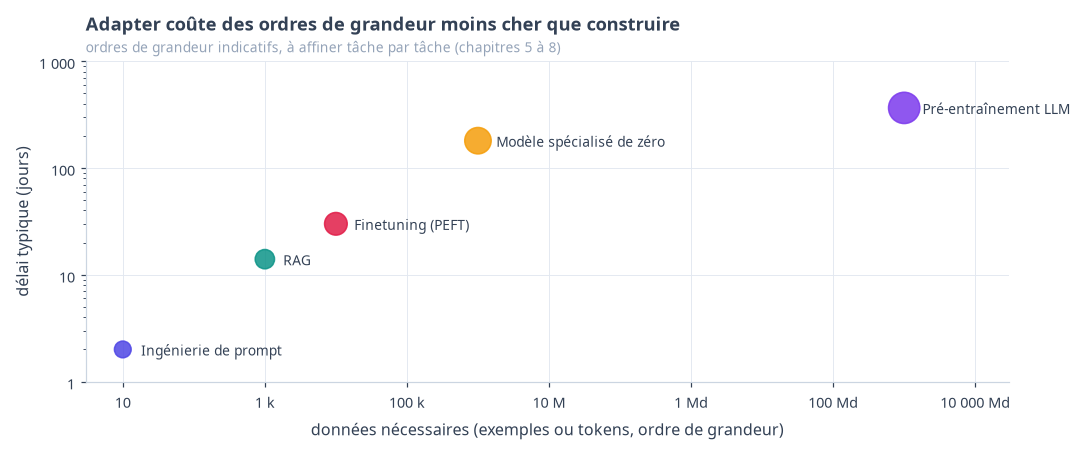

In [20]:
eff = pd.DataFrame({
    "technique": ["Ingénierie de prompt", "RAG", "Finetuning (PEFT)", "Modèle spécialisé de zéro", "Pré-entraînement LLM"],
    "exemples": [10, 1e3, 1e4, 1e6, 1e12],
    "délai (jours)": [2, 14, 30, 180, 365],
    "couleur": [INDIGO, TEAL, ROSE, AMBER, VIOLET],
})
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.scatter(eff["exemples"], eff["délai (jours)"], s=[120, 160, 220, 300, 420], c=eff["couleur"], alpha=0.85, zorder=5)
for _, r in eff.iterrows():
    ax.annotate(r["technique"], (r["exemples"], r["délai (jours)"]), textcoords="offset points",
                xytext=(12, -4), fontsize=9)
ax.set_xscale("log"); ax.set_yscale("log"); c1.human_log(ax, "x"); c1.plain_log(ax, "y")
ax.set_xlim(3, 3e13); ax.set_ylim(1, 1000)
ax.set_xlabel("données nécessaires (exemples ou tokens, ordre de grandeur)")
ax.set_ylabel("délai typique (jours)")
c1.title_sub(ax, "Adapter coûte des ordres de grandeur moins cher que construire",
             "ordres de grandeur indicatifs, à affiner tâche par tâche (chapitres 5 à 8)")
plt.tight_layout(); plt.show()

> **À retenir.** On adapte un modèle de fondation par le **prompt** (instructions,
> exemples), par le **contexte** récupéré (RAG) ou par le **finetuning** (poids modifiés).
> Les deux premiers sont rapides et peu gourmands en données ; c'est par eux qu'on commence.

## 8. Des modèles de fondation à l'AI engineering (section *From Foundation Models to AI Engineering*)

L'**AI engineering** désigne la construction d'applications **sur** des modèles de
fondation existants, là où le ML engineering classique développait ses propres modèles.
Le livre identifie trois facteurs qui, ensemble, expliquent l'essor fulgurant de la
discipline.

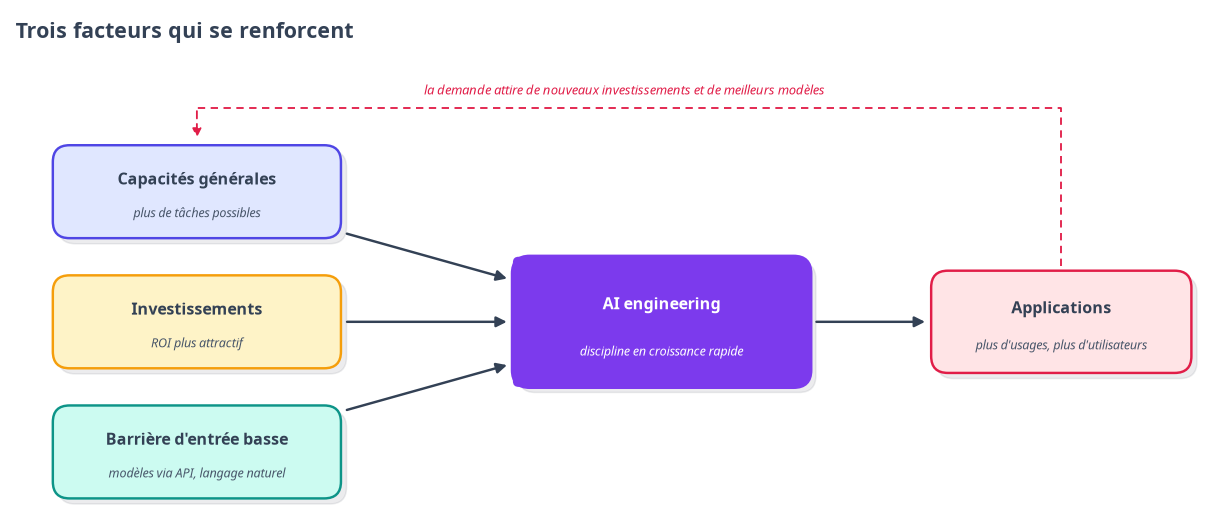

In [21]:
d = Diagram(13, 4.9, title="Trois facteurs qui se renforcent")
d.box("f1", 2.0, 3.5, "Capacités générales", sub="plus de tâches possibles", color=INDIGO, w=3.1, h=1.0)
d.box("f2", 2.0, 2.1, "Investissements", sub="ROI plus attractif", color=AMBER, w=3.1, h=1.0)
d.box("f3", 2.0, 0.7, "Barrière d'entrée basse", sub="modèles via API, langage naturel", color=TEAL, w=3.1, h=1.0)
d.box("ae", 7.0, 2.1, "AI engineering", sub="discipline en croissance rapide", color=VIOLET, kind="model", w=3.2, h=1.4, filled=True)
d.box("apps", 11.3, 2.1, "Applications", sub="plus d'usages, plus d'utilisateurs", color=ROSE, w=2.8, h=1.1)
for f in ["f1", "f2", "f3"]:
    d.arrow(f, "ae")
d.arrow("ae", "apps")
d.line([(11.3, 2.7), (11.3, 4.4), (2.0, 4.4), (2.0, 4.05)], color=ROSE, style="dashed")
d.note(6.6, 4.6, "la demande attire de nouveaux investissements et de meilleurs modèles", color=ROSE, fontsize=8.5)
d.show()

**Une baisse de coût vertigineuse.** Le livre rapporte qu'un responsable de Scribd a vu le
coût estimé de ses usages d'IA baisser de **deux ordres de grandeur** entre avril 2022 et
avril 2023. Traduisons : une division par 100 en 12 mois correspond à une division par 2
tous les $12 / \log_2(100) \approx 1{,}8$ mois. À ce rythme, une application qui coûtait
100 000 $ par mois n'en coûte plus que 1 000 un an plus tard : des cas d'usage hier
déraisonnables deviennent rentables.

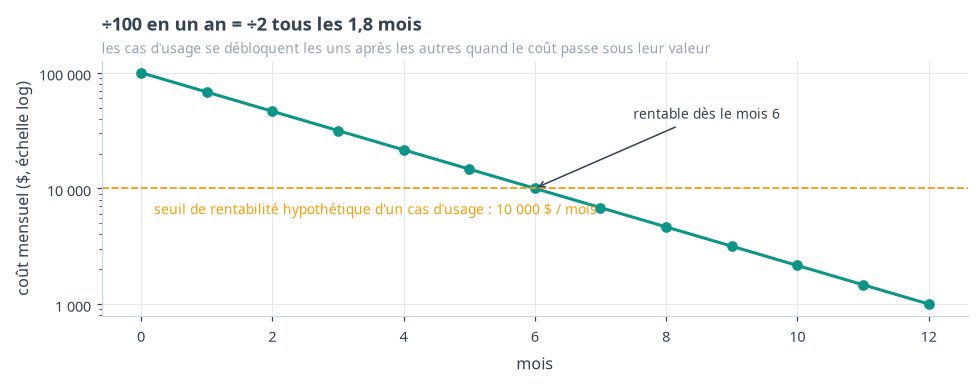

In [22]:
months = np.arange(0, 13)
halving = 12 / np.log2(100)
cost = 100_000 * 0.5 ** (months / halving)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(months, cost, "o-", color=TEAL)
ax.set_yscale("log"); c1.plain_log(ax)
ax.axhline(10_000, color=AMBER, ls="--", lw=1.2)
ax.text(0.2, 8_000, "seuil de rentabilité hypothétique d'un cas d'usage : 10 000 $ / mois", color=AMBER,
        fontsize=9, va="top")
cross = months[cost <= 10_000][0]
ax.annotate(f"rentable dès le mois {cross}", (cross, cost[cross]), xytext=(cross + 1.5, 40_000),
            arrowprops=dict(arrowstyle="->", color=SLATE), fontsize=9)
ax.set_xlabel("mois"); ax.set_ylabel("coût mensuel ($, échelle log)")
c1.title_sub(ax, "÷100 en un an = ÷2 tous les 1,8 mois",
             "les cas d'usage se débloquent les uns après les autres quand le coût passe sous leur valeur")
plt.tight_layout(); plt.show()

Le troisième facteur, la **barrière d'entrée basse**, est sans doute le plus important : un
modèle accessible par un appel d'API, qu'on pilote en langage naturel, met la construction
d'applications d'IA à la portée de n'importe quel développeur (et même de non-développeurs).
Le livre explique aussi le choix du terme : « ML engineering » ne rend pas compte des
différences importantes (cours 4), et les termes en « -Ops » insistent trop sur
l'exploitation alors que le cœur du travail est d'**adapter** (d'« ingénierer ») les modèles.

> **À retenir.** Capacités générales + investissements + barrière d'entrée basse : les
> trois facteurs s'entretiennent et ont fait de l'AI engineering l'une des disciplines
> d'ingénierie à la croissance la plus rapide.

## Synthèse

- L'**auto-supervision** (les cibles sont tirées des données elles-mêmes) supprime le
  coût d'étiquetage ; une séquence de $n$ tokens donne $n$ exemples, traités en une passe.
  La perte est l'entropie croisée, son exponentielle la perplexité.
- L'**échelle** se mesure en paramètres ($N \approx 12 L d^2 + Vd$), en données
  (≈ 20 tokens par paramètre à l'optimum de Chinchilla, souvent bien plus aujourd'hui) et
  en calcul ($C \approx 6ND$, jusqu'à $10^{25}$ FLOP).
- Les **modèles de fondation** étendent les LLM à d'autres modalités (une image devient
  une séquence de patchs ; CLIP apprend par contraste sur des paires image-légende) et
  passent du spécialisé au **généraliste**.
- On les **adapte** par le prompt, le RAG ou le finetuning, pour une fraction du coût
  d'un entraînement.
- Trois facteurs (capacités, investissements, barrière d'entrée) expliquent l'essor de
  l'**AI engineering**.

**Liens.** Le chapitre 2 détaille les données, l'architecture, les lois d'échelle et le
post-entraînement ; le chapitre 6 revient sur les embeddings et le RAG ; le chapitre 7 sur
le finetuning. Le cours 3 passe des modèles aux **applications** : cas d'usage et
planification.

In [23]:
llm.free_gpu()